# Experiment 182 · Periodic replay over the online stream

**Complete** · All full-stream comparisons saved · ETA 0h 00m 00s  
2026-11-13T14:47:54.165954+01:00 · PID 21092

All arms use one singleton AdamW update per arrival at ¼×. Starting from each seed’s original 8,000-arrival calibration checkpoint, 0%, 12.5%, 25%, and 50% replay process the same remaining stream. Replay replaces the current image every eighth, fourth, or second arrival, respectively. The schedules are nested. A historical image is drawn from ages 256–2,048 using a fixed causal age schedule. Each model seed has two fresh mask streams, paired across all fractions.

The primary endpoints are final masked MSE on the fixed 512-image unseen bank from Experiment 181 and the fixed 128-image historical bank. Banks use two fixed mask draws. Incoming loss measures reconstruction before updating on a common sampled set of arriving images. This tests plasticity as current-image exposure falls. The frozen scene probe and unseen-bank RankMe measure representation quality.

The preflight exactly reproduced a paused replacement replay after restoring the model and optimizer.

| Seed | Mask draw | Replay fraction | Arrivals | Replay updates | Current updates | Train time |
| --- | --- | --- | --- | --- | --- | --- |
 | 2026 | 1 | 0% | 72,000/72,000 | 0 | 72,000 | 0h 09m 27s | 
 | 2026 | 1 | 12.5% | 72,000/72,000 | 9,000 | 63,000 | 0h 09m 11s | 
 | 2026 | 1 | 25% | 72,000/72,000 | 18,000 | 54,000 | 0h 09m 13s | 
 | 2026 | 1 | 50% | 72,000/72,000 | 36,000 | 36,000 | 0h 09m 10s | 
 | 2026 | 2 | 0% | 72,000/72,000 | 0 | 72,000 | 0h 09m 10s | 
 | 2026 | 2 | 12.5% | 72,000/72,000 | 9,000 | 63,000 | 0h 09m 17s | 
 | 2026 | 2 | 25% | 72,000/72,000 | 18,000 | 54,000 | 0h 09m 10s | 
 | 2026 | 2 | 50% | 72,000/72,000 | 36,000 | 36,000 | 0h 09m 08s | 
 | 2027 | 1 | 0% | 72,000/72,000 | 0 | 72,000 | 0h 09m 08s | 
 | 2027 | 1 | 12.5% | 72,000/72,000 | 9,000 | 63,000 | 0h 09m 08s | 
 | 2027 | 1 | 25% | 72,000/72,000 | 18,000 | 54,000 | 0h 09m 12s | 
 | 2027 | 1 | 50% | 72,000/72,000 | 36,000 | 36,000 | 0h 09m 11s | 
 | 2027 | 2 | 0% | 72,000/72,000 | 0 | 72,000 | 0h 09m 09s | 
 | 2027 | 2 | 12.5% | 72,000/72,000 | 9,000 | 63,000 | 0h 09m 11s | 
 | 2027 | 2 | 25% | 72,000/72,000 | 18,000 | 54,000 | 0h 09m 09s | 
 | 2027 | 2 | 50% | 72,000/72,000 | 36,000 | 36,000 | 0h 09m 11s | 
 | 2028 | 1 | 0% | 72,000/72,000 | 0 | 72,000 | 0h 09m 10s | 
 | 2028 | 1 | 12.5% | 72,000/72,000 | 9,000 | 63,000 | 0h 09m 10s | 
 | 2028 | 1 | 25% | 72,000/72,000 | 18,000 | 54,000 | 0h 09m 09s | 
 | 2028 | 1 | 50% | 72,000/72,000 | 36,000 | 36,000 | 0h 09m 12s | 
 | 2028 | 2 | 0% | 72,000/72,000 | 0 | 72,000 | 0h 09m 12s | 
 | 2028 | 2 | 12.5% | 72,000/72,000 | 9,000 | 63,000 | 0h 09m 14s | 
 | 2028 | 2 | 25% | 72,000/72,000 | 18,000 | 54,000 | 0h 09m 12s | 
 | 2028 | 2 | 50% | 72,000/72,000 | 36,000 | 36,000 | 0h 09m 18s | 

## Latest matched readouts

| Replay | Arrivals | Paired runs | Unseen gain | Historical gain | Incoming gain | Probe gain | RankMe gain | Seeds improving unseen / historical |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | 12.5% | 72,000 | 6 | +0.04732 | +0.04288 | +0.01696 | +0.03 pp | +0.56448 | 3 / 3 of 3 | 
 | 25% | 72,000 | 6 | +0.05980 | +0.04890 | +0.01997 | +0.52 pp | +0.94709 | 3 / 3 of 3 | 
 | 50% | 72,000 | 6 | +0.06569 | +0.05210 | +0.02655 | -0.19 pp | +1.73989 | 3 / 3 of 3 | 

Positive gains favor replay. Each seed contributes its mean over matched masks, and seeds receive equal weight. Shading shows the range of seed means. The JSON retains per-seed and per-mask differences. Probe accuracy is measured at baseline and every 24,000 online arrivals.


In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-periodic-replay')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


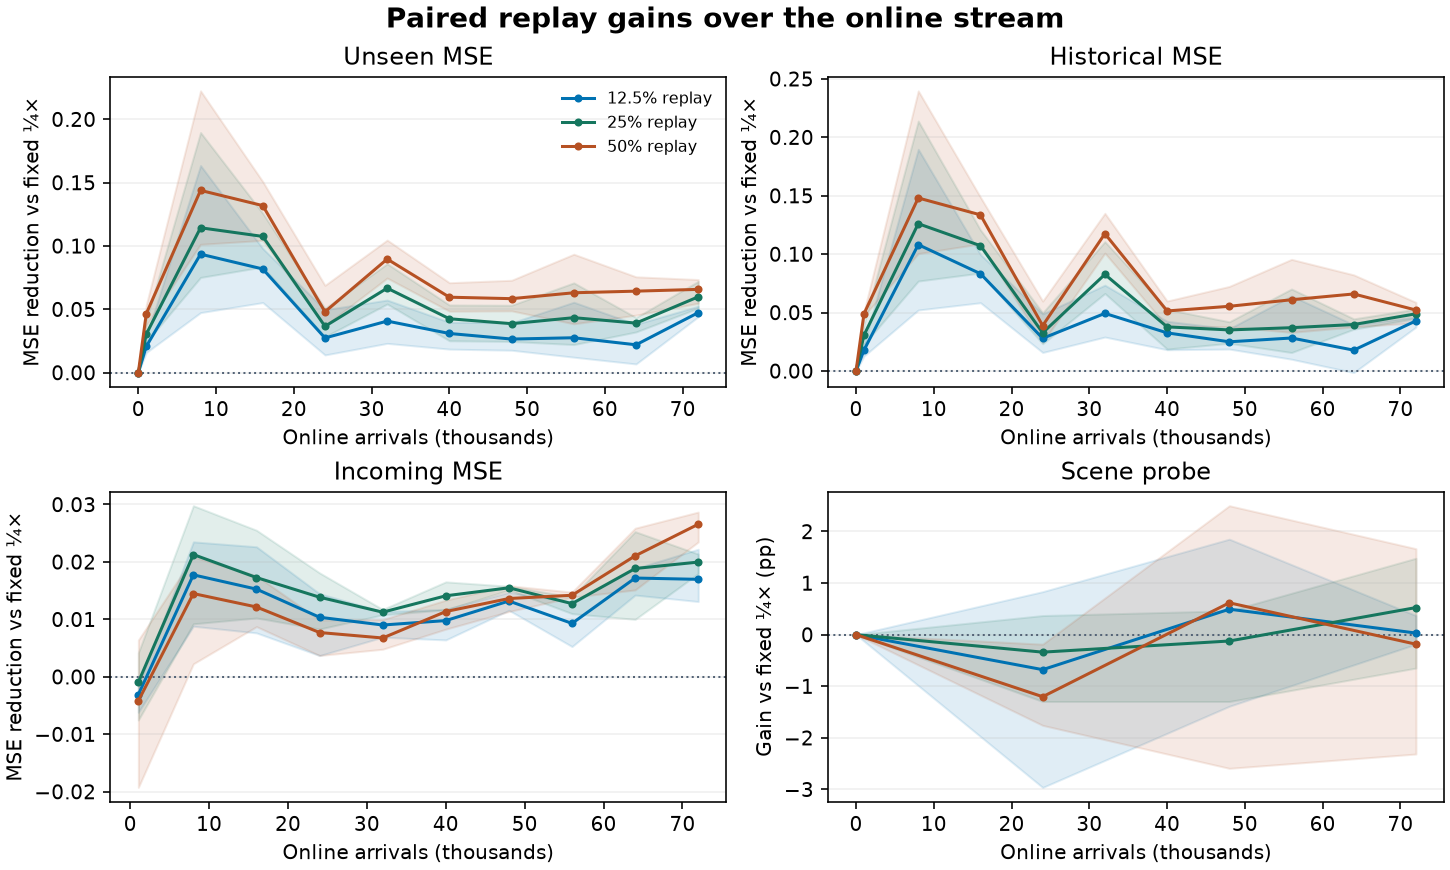